## Подготовка данных

In [1]:
# берем таблицу образцов
samples <- read.csv(
  "metadata/samplesheet.csv",
  stringsAsFactors = FALSE
)

samples

sample,run_accession,fastq_1,fastq_2
<chr>,<chr>,<chr>,<chr>
N3,SRR13344595,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_2.fastq.gz
N4,SRR13344596,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_2.fastq.gz
N5,SRR13344597,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_2.fastq.gz
N13,SRR13344598,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_2.fastq.gz
N17,SRR13344599,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_2.fastq.gz
N19,SRR13344600,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_2.fastq.gz
N21,SRR13344601,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_2.fastq.gz
N22,SRR13344602,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_2.fastq.gz
T3,SRR13344603,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_2.fastq.gz


In [2]:
# добавим пациента и тип ткани
samples$patient <- sub("^[NT]", "", samples$sample)

samples$condition <- ifelse(
  startsWith(samples$sample, "N"),
  "normal",
  "tumor"
)

samples[, c("sample", "patient", "condition")]

sample,patient,condition
<chr>,<chr>,<chr>
N3,3,normal
N4,4,normal
N5,5,normal
N13,13,normal
N17,17,normal
N19,19,normal
N21,21,normal
N22,22,normal
T3,3,tumor


In [3]:
# проверим пути к файлам Salmon
files <- file.path("results", "salmon", samples$sample, "quant.sf")
names(files) <- samples$sample

files
all(file.exists(files))

N3                            N4 
 "results/salmon/N3/quant.sf"  "results/salmon/N4/quant.sf" 
                           N5                           N13 
 "results/salmon/N5/quant.sf" "results/salmon/N13/quant.sf" 
                          N17                           N19 
"results/salmon/N17/quant.sf" "results/salmon/N19/quant.sf" 
                          N21                           N22 
"results/salmon/N21/quant.sf" "results/salmon/N22/quant.sf" 
                           T3                            T4 
 "results/salmon/T3/quant.sf"  "results/salmon/T4/quant.sf" 
                           T5                           T13 
 "results/salmon/T5/quant.sf" "results/salmon/T13/quant.sf" 
                          T17                           T19 
"results/salmon/T17/quant.sf" "results/salmon/T19/quant.sf" 
                          T21                           T22 
"results/salmon/T21/quant.sf" "results/salmon/T22/quant.sf"

[1] TRUE

In [4]:
# берем таблицу tx2gene
annotation <- read.delim(
  "data/reference/tx2gene_gencode50.tsv",
  stringsAsFactors = FALSE
)

tx2gene <- annotation[, c("transcript_id", "gene_id")]

head(tx2gene)

,transcript_id,gene_id
,<chr>,<chr>
1,ENST00000832824.1,ENSG00000290825.2
2,ENST00000832825.1,ENSG00000290825.2
3,ENST00000832826.1,ENSG00000290825.2
4,ENST00000832827.1,ENSG00000290825.2
5,ENST00000832828.1,ENSG00000290825.2
6,ENST00000832829.1,ENSG00000290825.2


In [5]:
# проверим, что каждый транскрипт встречается в таблице только один раз и нет пропусков
anyDuplicated(tx2gene$transcript_id)
anyNA(tx2gene)
any(tx2gene$transcript_id == "" | tx2gene$gene_id == "")
any(tx2gene$transcript_id == " " | tx2gene$gene_id == " ")

[1] 0

[1] FALSE

[1] FALSE

[1] FALSE

In [6]:
# запускаем расчет tximport

library(tximport)

txi <- tximport(
  files,
  type = "salmon",
  tx2gene = tx2gene,
  countsFromAbundance = "no"  # суммируем исходные оценки NumReads, а не пересчитываем количества из TPM
)

reading in files with read.delim (install 'readr' package for speed up)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [7]:
# смотрим на txi

names(txi)                                         # компоненты
dim(txi$counts)                                    # число генов и образцов
txi$counts[1:6, 1:4]                               # небольшой фрагмент матрицы
identical(colnames(txi$counts), samples$sample)    # совпадают ли имена и порядок образцов в матрице с таблицей метаданных; ожидаем TRUE

[1] "abundance"           "counts"              "length"             
[4] "countsFromAbundance"

[1] 78292    16

,N3,N4,N5,N13
ENSG00000000003.18,255.593,33.551,26.878,26.151
ENSG00000000005.7,0.000,0.000,0.000,0.000
ENSG00000000419.16,91.554,104.832,64.114,83.004
ENSG00000000457.16,105.955,52.975,64.579,66.067
ENSG00000000460.19,42.575,41.289,45.346,39.804
ENSG00000000938.15,17.951,44.018,28.038,85.014


[1] TRUE

In [8]:
# проверяем сходится ли TPM
colSums(txi$abundance)

N3    N4    N5   N13   N17   N19   N21   N22    T3    T4    T5   T13   T17 
1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 
  T19   T21   T22 
1e+06 1e+06 1e+06

In [9]:
# обозначим пациента и ткань как категории (факторы)

samples$patient <- factor(samples$patient)

samples$condition <- factor(
  samples$condition,
  levels = c("normal", "tumor")
)

rownames(samples) <- samples$sample

samples

,sample,run_accession,fastq_1,fastq_2,patient,condition
,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
N3,N3,SRR13344595,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_2.fastq.gz,3,normal
N4,N4,SRR13344596,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_2.fastq.gz,4,normal
N5,N5,SRR13344597,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_2.fastq.gz,5,normal
N13,N13,SRR13344598,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_2.fastq.gz,13,normal
N17,N17,SRR13344599,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_2.fastq.gz,17,normal
N19,N19,SRR13344600,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_2.fastq.gz,19,normal
N21,N21,SRR13344601,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_2.fastq.gz,21,normal
N22,N22,SRR13344602,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_2.fastq.gz,22,normal
T3,T3,SRR13344603,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_2.fastq.gz,3,tumor


In [10]:
#  проверка на парность образцов
table(samples$patient, samples$condition)

    
     normal tumor
  13      1     1
  17      1     1
  19      1     1
  21      1     1
  22      1     1
  3       1     1
  4       1     1
  5       1     1

In [11]:
# объединяем результаты tximport, метаданные и задаем дизайн эксперимента в объект DESeq2

library(DESeq2)

stopifnot(
  identical(colnames(txi$counts), rownames(samples))
)

dds <- DESeqDataSetFromTximport(
  txi = txi,                       # результаты квантификации, суммированные по генам
  colData = samples,               # метаданные образцов
  design = ~ patient + condition   # формула, которая указывает, какие колонки метаданных использовать в модели в качестве факторов
)

dds

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    Filter, Find, Map, Position, Reduce, anyDuplicated, aperm, append,
    as.data.frame, basename, cbind, colnames, dirname, do.call,
    duplicated, eval, evalq, get, grep, grepl, is.unsorted, lapply,
    mapply, match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    rank, rbind, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

class: DESeqDataSet 
dim: 78292 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(78292): ENSG00000000003.18 ENSG00000000005.7 ...
  ENSG00000310795.1 ENSG00000310796.1
rowData names(0):
colnames(16): N3 N4 ... T21 T22
colData names(6): sample run_accession ... patient condition

In [12]:
# формула дизайна
design(dds)

~patient + condition

In [13]:
# правило для фильтрации
keep <- rowSums(counts(dds) >= 10) >= 8    # оставляем гены с ≥10 фрагментами хотя бы в 8 из 16 образцов:

table(keep)

keep
FALSE  TRUE 
61295 16997 

In [14]:
# фильтрация
dds_filtered <- dds[keep, ]

dim(dds_filtered)

[1] 16997    16

## Нормализация


In [15]:
# рассчитываем нормировочные коэффициенты
dds_filtered <- estimateSizeFactors(dds_filtered)

using 'avgTxLength' from assays(dds), correcting for library size



In [16]:
# смотрим фрагмент сохранённой матрицы поправок
normalizationFactors(dds_filtered)[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,1.0395933,1.1396911,1.3194889,0.8358717
ENSG00000000419.16,1.0132545,0.9878762,0.9238019,0.9319046
ENSG00000000457.16,0.9885598,1.1952114,1.0667879,0.8648978
ENSG00000000460.19,1.3304352,0.9042105,0.9397541,0.9041359
ENSG00000000938.15,0.9752313,1.0890277,0.9304232,1.1470799
ENSG00000000971.19,1.1008937,0.9662897,0.9711407,1.0141126


In [17]:
# получаем матрицу нормализованных каунтов и посмотреть ее фрагмент
normalized_counts <- counts(dds_filtered, normalized = TRUE)
normalized_counts[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,246.25015,29.83265,20.46247,31.10525
ENSG00000000419.16,90.79654,106.28863,69.27892,89.06492
ENSG00000000457.16,107.22669,44.34362,60.93058,76.30959
ENSG00000000460.19,32.32025,45.34342,47.88487,44.24114
ENSG00000000938.15,18.45716,40.40301,30.09383,74.10120
ENSG00000000971.19,457.80988,1003.83972,894.82403,971.29256


## PCA

In [18]:
# преобразуем значения с учётом дизайна при оценке дисперсии
vsd <- vst(dds_filtered, blind = FALSE)

In [19]:
# смотрим фрагмент преобразованных данных
assay(vsd)[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,7.979604,5.160215,4.716539,5.211028
ENSG00000000419.16,6.598300,6.812465,6.235454,6.572256
ENSG00000000457.16,6.824464,5.653840,6.065690,6.364350
ENSG00000000460.19,5.257904,5.682313,5.752241,5.650889
ENSG00000000938.15,4.600259,5.535753,5.170793,6.325093
ENSG00000000971.19,8.857929,9.980174,9.815395,9.932919


In [20]:
# для графика
options(
  repr.plot.width = 12,
  repr.plot.height = 8
)

using ntop=500 top features by variance



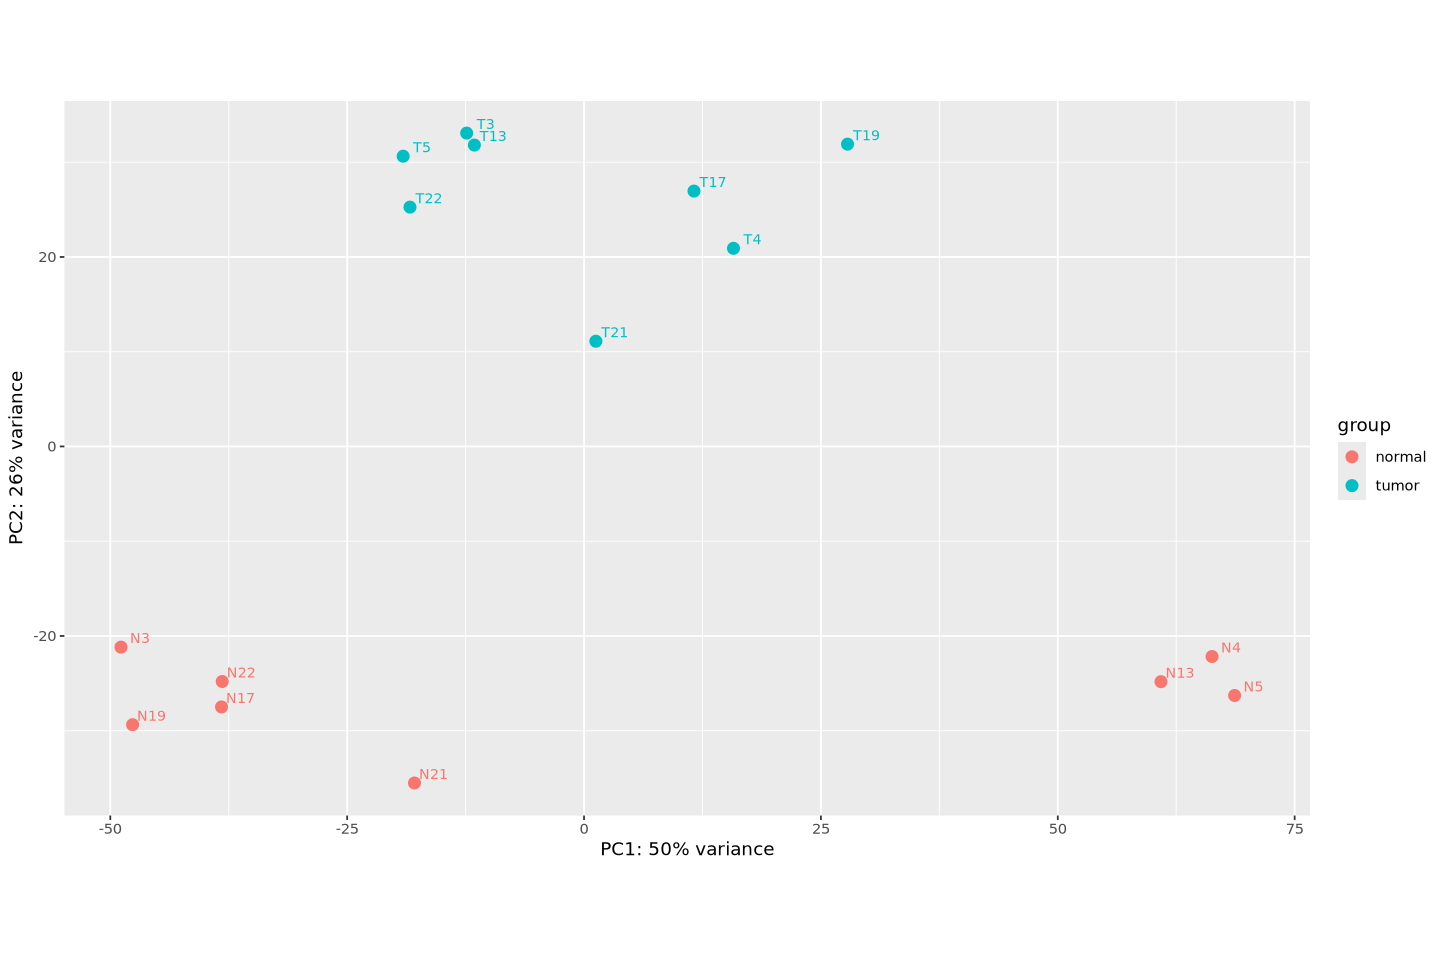

In [21]:
# расчет PCA + график с подписями
plotPCA(vsd, intgroup = "condition", ntop = 500) +
  ggplot2::geom_text(
    ggplot2::aes(label = name),
    nudge_x = 2,        # сдвиг вправо в единицах оси PC1
    vjust = -0.4,
    size = 3,
    show.legend = FALSE
  )

## DE

In [22]:
#  разброс и эффект условия для каждого гена
dds_de <- DESeq(dds_filtered)

using pre-existing normalization factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [23]:
mcols(dds_de)[1:5, c("baseMean", "dispGeneEst", "dispFit", "dispersion")]

DataFrame with 5 rows and 4 columns
                    baseMean dispGeneEst   dispFit dispersion
                   <numeric>   <numeric> <numeric>  <numeric>
ENSG00000000003.18  142.3203   0.7149209  0.241790  0.5893431
ENSG00000000419.16  103.2581   0.0437669  0.249620  0.0812830
ENSG00000000457.16   81.8879   0.0541246  0.257066  0.0920941
ENSG00000000460.19   63.0704   0.1038368  0.267800  0.1387434
ENSG00000000938.15   36.4418   0.2331237  0.301931  0.2505116

In [24]:
# результаты для опухоли относительно нормы
res <- results(
  dds_de,
  contrast = c("condition", "tumor", "normal"),
  alpha = 0.05
)

as.data.frame(head(res))

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000000003.18,142.32034,-0.4182257,0.5584378,-0.7489208,0.453904934,0.62550853
ENSG00000000419.16,103.25811,0.4370072,0.2181943,2.0028351,0.045194996,0.12703479
ENSG00000000457.16,81.88791,-0.1368821,0.2349042,-0.5827146,0.560085447,0.71384016
ENSG00000000460.19,63.07043,0.8654174,0.2864111,3.0215922,0.002514491,0.01399447
ENSG00000000938.15,36.44181,0.5512006,0.3832175,1.4383492,0.150334996,0.29854468
ENSG00000000971.19,541.92578,-1.0396508,0.3820779,-2.7210440,0.006507610,0.02925412


## Результаты

In [25]:
# выбираем гены с рассчитанным padj ниже 0,05
res_sig <- res[!is.na(res$padj) & res$padj < 0.05, ]

c(
  total = nrow(res_sig),
  higher_in_tumor = sum(res_sig$log2FoldChange > 0),
  lower_in_tumor = sum(res_sig$log2FoldChange < 0)
)

total higher_in_tumor  lower_in_tumor 
           4424            2170            2254

In [26]:
# сводка по величине изменений среди значимых генов
summary(abs(res_sig$log2FoldChange))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.2994  0.8299  1.2116  1.4608  1.8172 10.7966 

In [27]:
# ген с самым большим изменением по модулю
as.data.frame(res_sig[which.max(abs(res_sig$log2FoldChange)), ])

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000220842.6,76.95507,-10.79665,2.297549,-4.699203,2.611792e-06,4.97869e-05


In [28]:
# нормализованные каунты этого гена для каждого пациента и условия
data.frame(
  patient = dds_de$patient,
  condition = dds_de$condition,
  normalized_count = counts(dds_de, normalized = TRUE)["ENSG00000220842.6", ]
)

,patient,condition,normalized_count
,<fct>,<fct>,<dbl>
N3,3,normal,247.79039
N4,4,normal,0.00000
N5,5,normal,135.14640
N13,13,normal,0.00000
N17,17,normal,147.11052
N19,19,normal,267.84993
N21,21,normal,159.31785
N22,22,normal,147.99533
T3,3,tumor,0.00000


### Коррекция эффектов

In [29]:
# названия коэффициентов рассчитанной модели
resultsNames(dds_de)

[1] "Intercept"                 "patient_17_vs_13"         
[3] "patient_19_vs_13"          "patient_21_vs_13"         
[5] "patient_22_vs_13"          "patient_3_vs_13"          
[7] "patient_4_vs_13"           "patient_5_vs_13"          
[9] "condition_tumor_vs_normal"

In [30]:
# уточняем log2FoldChange методом apeglm для всех проанализированных генов
res_shrunk <- lfcShrink(
  dds_de,
  coef = "condition_tumor_vs_normal",
  res = res,
  type = "apeglm"
)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



In [31]:
# сранвнение гена с наибольшим изменением: исходный результат и результат после shrinkage
as.data.frame(res["ENSG00000220842.6", ])
as.data.frame(res_shrunk["ENSG00000220842.6", ])

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000220842.6,76.95507,-10.79665,2.297549,-4.699203,2.611792e-06,4.97869e-05


,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000220842.6,76.95507,-0.1007954,0.541825,2.611792e-06,4.97869e-05


In [32]:
# проверка метода apeglm

# фиксируем случайные старты для воспроизводимости
set.seed(593)

# повторяем apeglm с другими начальными точками поиска
res_shrunk_check <- lfcShrink(
  dds_de,
  coef = "condition_tumor_vs_normal",
  res = res,
  type = "apeglm",
  apeMethod = "nbinomC*"
)

# сравниваем оценки выбранного гена
c(
  initial = res_shrunk["ENSG00000220842.6", "log2FoldChange"],
  check = res_shrunk_check["ENSG00000220842.6", "log2FoldChange"]
)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



initial.ENSG00000220842.6   check.ENSG00000220842.6 
               -0.1007954                -0.1002608

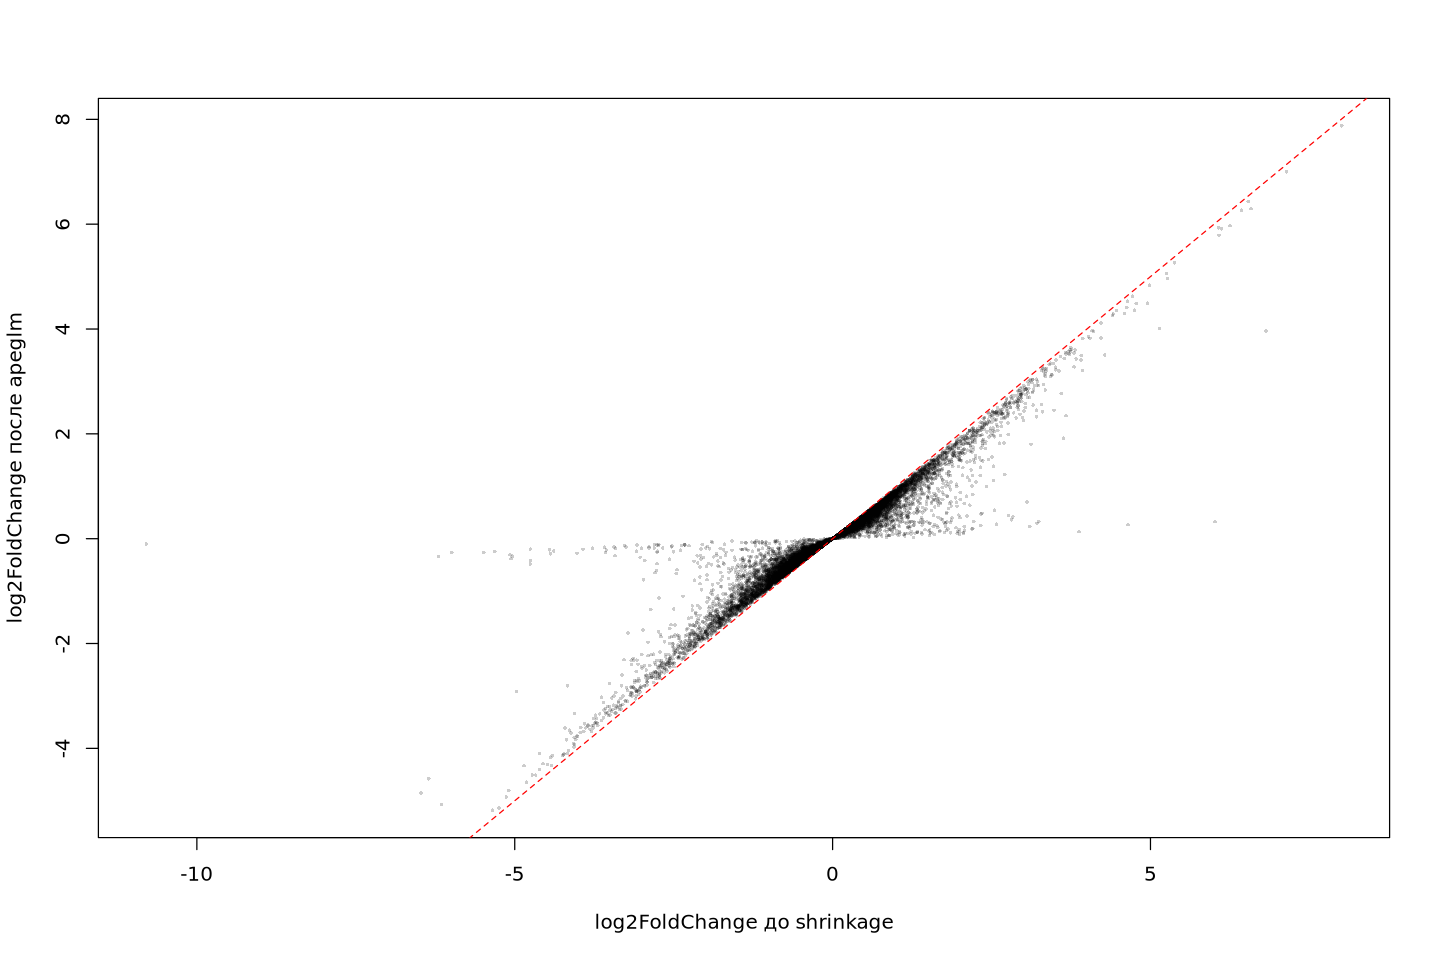

In [33]:
# сравним эффекты до и после shrinkage
plot(
  res$log2FoldChange,
  res_shrunk$log2FoldChange,
  xlab = "log2FoldChange до shrinkage",
  ylab = "log2FoldChange после apeglm",
  pch = 16,
  cex = 0.4,
  col = rgb(0, 0, 0, 0.2)
)

# Линия, на которой исходная и новая оценки совпадают
abline(a = 0, b = 1, col = "red", lty = 2)

In [34]:
# сводка по величине изменений среди значимых генов до коррекции
summary(abs(res_sig$log2FoldChange))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.2994  0.8299  1.2116  1.4608  1.8172 10.7966 

In [35]:
# сводка скорректированных эффектов для ранее отобранных значимых генов
summary(abs(res_shrunk[rownames(res_sig), "log2FoldChange"]))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.1008  0.7098  0.9822  1.2288  1.4833  7.8773 


!!!

После LFC shrinkage методом apeglm медиана абсолютного log2FoldChange среди 4 424 генов с исходным padj < 0,05 уменьшилась с 1,21 до 0,98. Центральные 50% оценок находятся в диапазоне 0,71–1,48 вместо 0,83–1,82. Максимальный модуль эффекта уменьшился с 10,80 до 7,88. 

Состав рассматриваемого набора генов не изменился: отбор основан на исходных padj.

### Графики

#### MA-plot

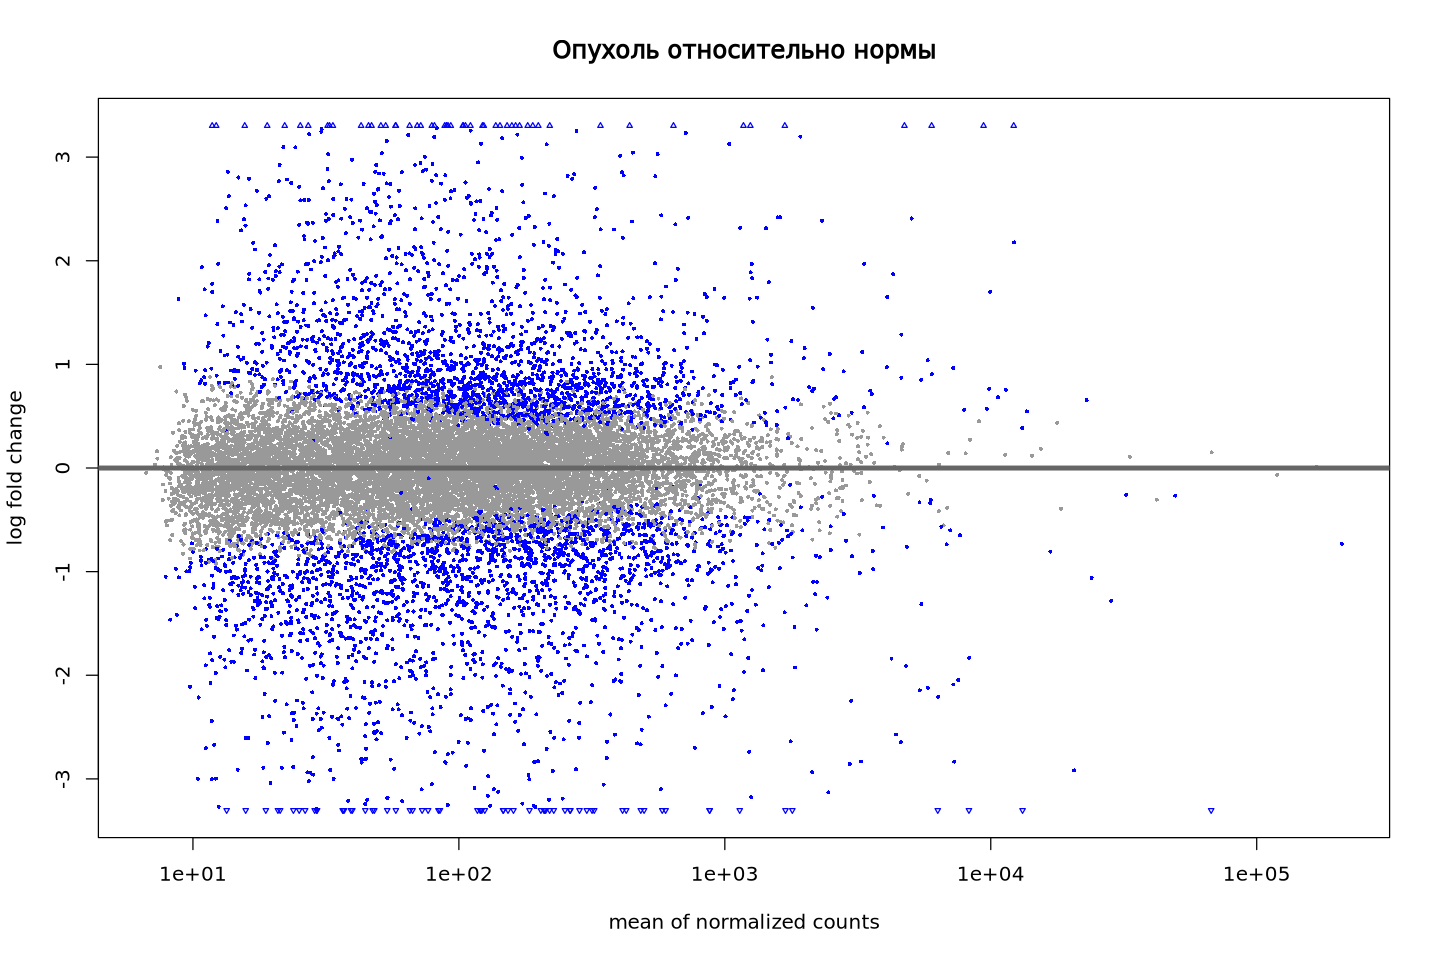

In [41]:
# берём эффекты после apeglm, а padj — из исходных результатов.
ma_res <- res_shrunk
ma_res$padj <- res$padj[match(rownames(ma_res), rownames(res))]

# выделяем цветом гены с padj < 0.05.
DESeq2::plotMA(ma_res, alpha = 0.05, main = "Опухоль относительно нормы")

#### Volcano plot

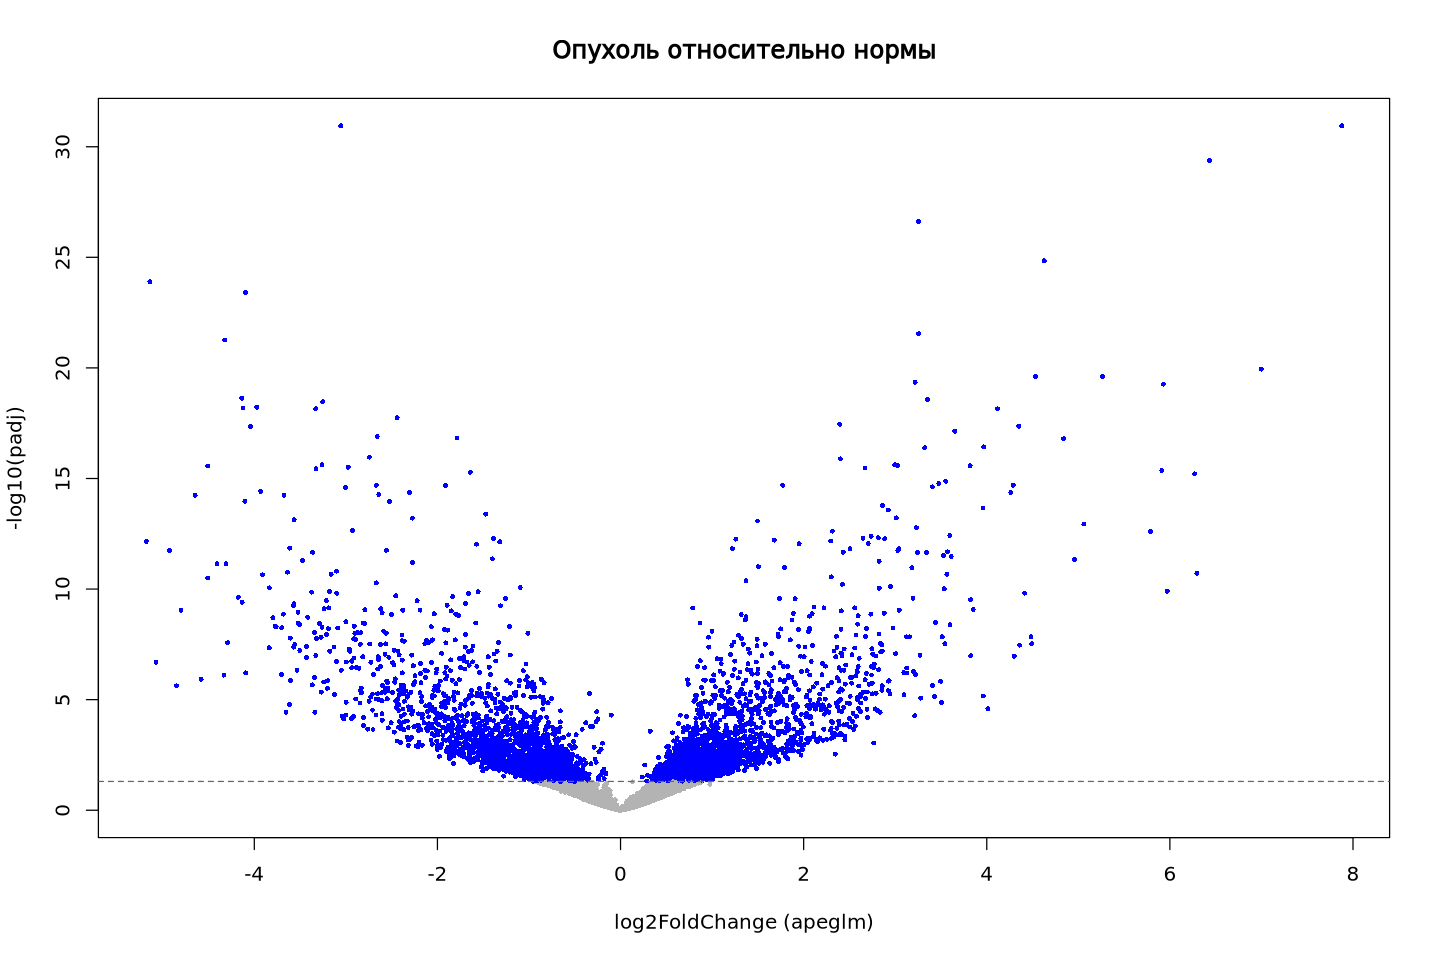

In [42]:
# сопоставляем эффекты apeglm и исходные padj по ID генов.
volcano <- data.frame(
  gene_id = rownames(res_shrunk),
  log2FC = res_shrunk$log2FoldChange,
  padj = res$padj[match(rownames(res_shrunk), rownames(res))]
)

# оставляем гены, для которых есть обе координаты.
volcano <- subset(volcano, is.finite(log2FC) & !is.na(padj))
volcano$y <- -log10(pmax(volcano$padj, .Machine$double.xmin))


plot(y ~ log2FC, data = volcano,
     col = ifelse(volcano$padj < 0.05, "blue", "grey70"),
     pch = 16, cex = 0.55,
     xlab = "log2FoldChange (apeglm)", ylab = "-log10(padj)",
     main = "Опухоль относительно нормы")
abline(h = -log10(0.05), lty = 2, col = "grey40")

In [43]:
# берем только синие точки
sig <- subset(volcano, padj < 0.05)

# сортируем в порядке убывания модуля эффекта
sig <- sig[order(abs(sig$log2FC), decreasing = TRUE), ]

# берём первые пять генов каждого направления
top_genes <- rbind(
  head(subset(sig, log2FC < 0), 6),
  head(subset(sig, log2FC > 0), 6)
)

# добавляем обозначения генов
top_genes$gene_name <- annotation$gene_name[
  match(top_genes$gene_id, annotation$gene_id)
]

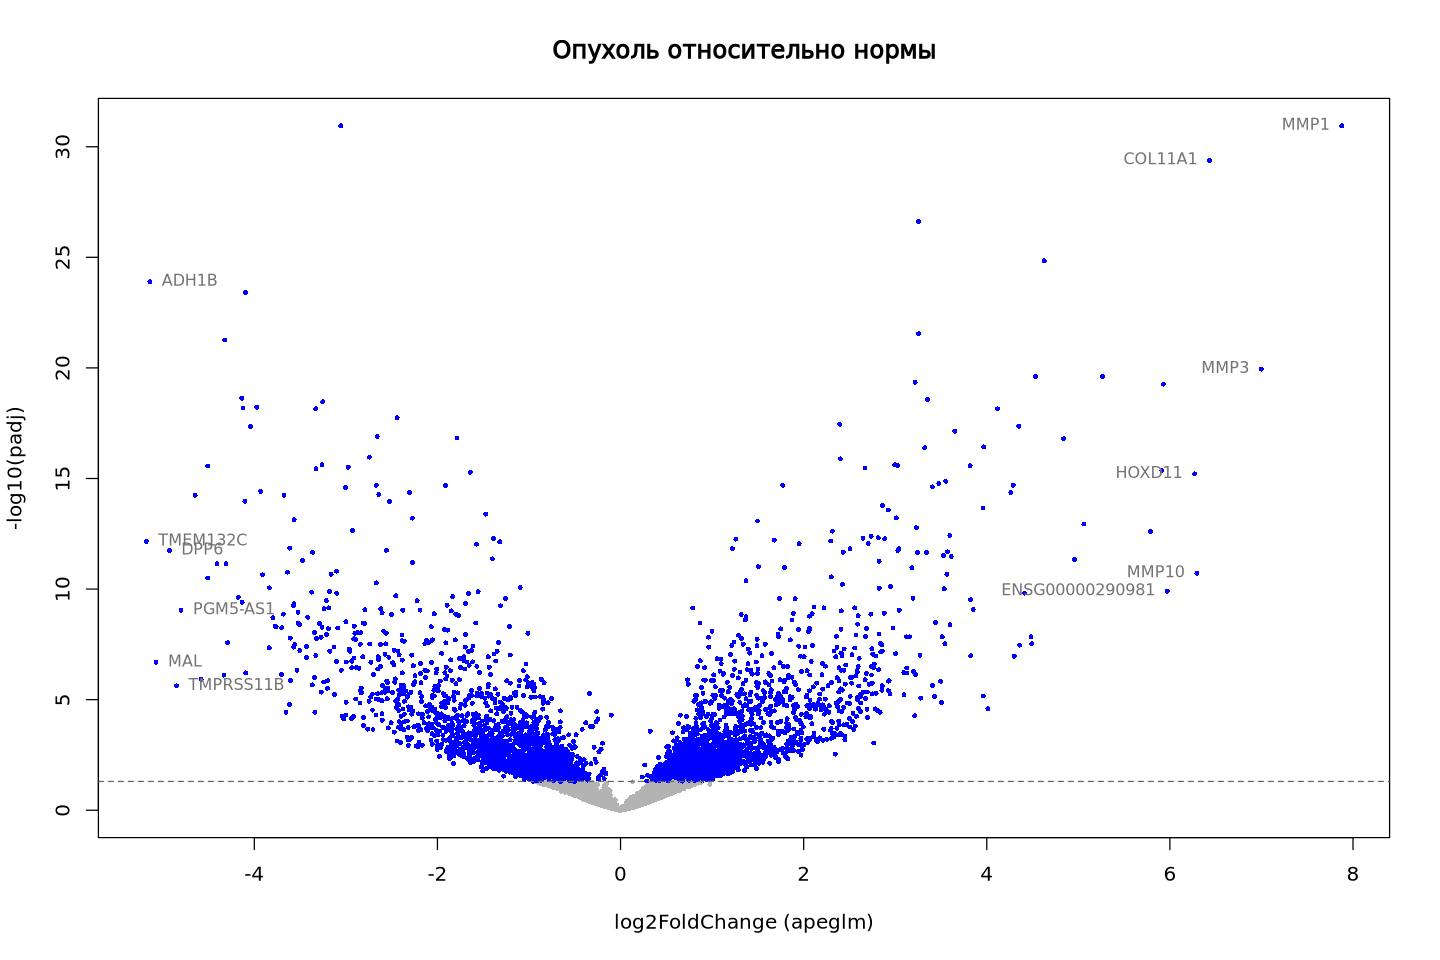

In [44]:
# рисуем график
plot(y ~ log2FC, data = volcano,
     col = ifelse(volcano$padj < 0.05, "blue", "grey70"),
     pch = 16, cex = 0.55,
     xlab = "log2FoldChange (apeglm)", ylab = "-log10(padj)",
     main = "Опухоль относительно нормы")
abline(h = -log10(0.05), lty = 2, col = "grey40")

# подписываем шесть выбранных точек
with(top_genes, text(log2FC, y, labels = gene_name,
                     pos = ifelse(log2FC < 0, 4, 2),
                     cex = 0.8, col = "grey45"))

#### Paired dot plots of normalized counts

In [47]:
# выбираем гены для парного дот-плота с нормализованными каунтами

# два гена, которые хотим посмотреть отдельно
special_ids <- c("ENSG00000290981.2", "ENSG00000164611.15")  # lncRNA и PTTG1

# среди остальных значимых генов сортируем по модулю эффекта
candidates <- subset(volcano, padj < 0.05 & !(gene_id %in% special_ids))
candidates <- candidates[order(abs(candidates$log2FC), decreasing = TRUE), ]

up <- head(subset(candidates, log2FC > 0), 2)
down <- head(subset(candidates, log2FC < 0), 2)

In [51]:
# собираем ID, названия и результаты DESeq2 в одну таблицу
ids <- c(up$gene_id, down$gene_id, special_ids)
selected <- data.frame(
  gene_id = ids,
  gene = annotation$gene_name[match(ids, annotation$gene_id)],
  log2FC = res_shrunk$log2FoldChange[match(ids, rownames(res_shrunk))],
  padj = res$padj[match(ids, rownames(res))]
)

selected <- selected[order(selected$log2FC, decreasing = TRUE), ]
selected

,gene_id,gene,log2FC,padj
,<chr>,<chr>,<dbl>,<dbl>
ENSG00000196611.7,ENSG00000196611.7,MMP1,7.877339,1.127261e-31
ENSG00000149968.13,ENSG00000149968.13,MMP3,6.997149,1.134754e-20
ENSG00000290981.2,ENSG00000290981.2,ENSG00000290981,5.970830,1.261473e-10
ENSG00000164611.15,ENSG00000164611.15,PTTG1,1.314751,7.237794e-03
ENSG00000196616.17,ENSG00000196616.17,ADH1B,-5.140875,1.276142e-24
ENSG00000181234.11,ENSG00000181234.11,TMEM132C,-5.180444,7.043087e-13


In [52]:
# достаем каунты для каждого образца
norm_counts <- DESeq2::counts(dds_de, normalized = TRUE)
panel_labels <- sprintf("%s\nlog2FC = %+.2f", selected$gene, selected$log2FC)

paired_counts <- do.call(rbind, lapply(seq_len(nrow(selected)), function(i) {
  data.frame(
    panel = panel_labels[i],
    patient = dds_de$patient,
    condition = dds_de$condition,
    count = norm_counts[selected$gene_id[i], ]
  )
}))

paired_counts$panel <- factor(paired_counts$panel, levels = panel_labels)

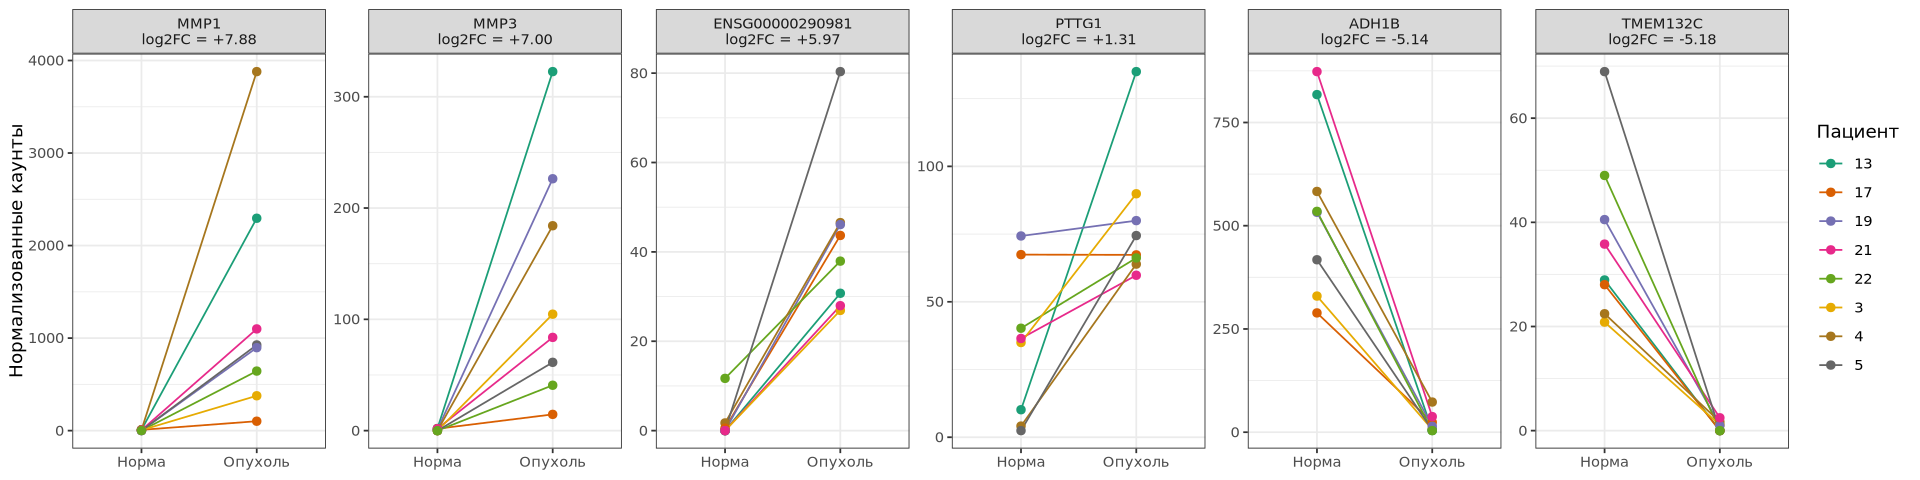

In [65]:
# график: один цвет на пациента, одна панель на ген
options(repr.plot.width = 16, repr.plot.height = 4)

ggplot2::ggplot(
  paired_counts,
  ggplot2::aes(x = condition, y = count, group = patient, colour = patient)
) +
  ggplot2::geom_line() +
  ggplot2::geom_point(size = 2) +
  ggplot2::facet_wrap(~ panel, scales = "free_y", nrow=1) +
  ggplot2::scale_x_discrete(labels = c(normal = "Норма", tumor = "Опухоль")) +
  ggplot2::scale_colour_brewer(palette = "Dark2", name = "Пациент") +
  ggplot2::labs(x = NULL, y = "Нормализованные каунты") +
  ggplot2::theme_bw() + 
  ggplot2::theme(
    legend.position = "right",
    plot.margin = ggplot2::margin(t = 5.5, r = 24, b = 5.5, l = 5.5)
  )